# Which categorisation of inter-syllable gaps does prosody support?

**Occurrence** = the gap between two consecutive syllables. Each gap has a 0/1 vector of prosodic features: the acoustic features of the syllable before and after, and the perceptual features (prominence, Begin/End of Foot, Group, Package, Period) of the tokens they belong to.

**Candidate categorisations** = every syntactic descriptor of the gap (constituency, dependency, POS of the words), alone and combined in pairs. We don't decide in advance which gap types exist: each candidate is tested the same way.

**Test** = the stability analysis of the word notebook. Each gap's prosodic neighbours are found once. For each candidate we ask how often a gap's neighbours share its category, compared with random relabellings, and summarise with the same kappa.

**Units** = the gaps themselves. In the word study, the occurrences of a lexeme were pooled into one unit. A gap has no lexical identity of that kind (word pairs are too rare to pool), and every candidate must be tested on the same units, so each gap is its own unit.

Then, for the best candidate:
* its stability matrix, showing where its categories overlap (Step 5);
* the split tests of the word notebook's Step 2, asking which descriptor divides each category (Step 6);
* the refined categorisation and its stability matrix (Step 7).

In [1]:
from collections import Counter, defaultdict
from itertools import combinations
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie/prosody_no_punct.conllu"

# ── Prosodic features ────────────────────────────────────────────────────
#   "all" : acoustic + perceptual | "acoustic" : syllable measures only | "perceptual" : prominence + Begin/End only
FEATURE_SET = "all"
PAIR_FEATURES = True         # NEW: add features of the pair of syllables (F0 jump, duration ratio), see Step 1
ACOUSTIC_MEASURES = ("Duration", "AvgHeightGlo", "PitchRangeGlo", "SlopeGlo",
                     "SemitonesFromUtteranceMean")
UNIT_LEVELS = ("Foot", "Group", "Package", "Period")
TOKEN_ANCHOR = "token"        # "token": both syllables get their token's Begin/End
                              # "syllable": Begin only on the token's first syllable, End only on its last
MIN_FEATURE_OCC = 10          # a feature seen fewer times is noise
DROP_UNMEASURED = True        # keep only gaps whose two syllables have every acoustic measure,
                              # so that a 0 always means "absent", never "not measured"
EXCLUDE_PILES = False         # True: drop gaps touching a disfluent pile
PILE_RELS = {"repair", "conj:dicto", "conj:reform"}

# ── Neighbourhoods (as SIM_THRESHOLD / MAX_NEIGHBOURS in the word notebook) ──
MAX_NEIGHBOURS = 20
MAX_DIFF = 6                  # neighbours differ on at most 6 features (one measure changing value = 2 differences)
CHUNK = 1000                  # gaps compared at a time (memory)

# ── Tests ────────────────────────────────────────────────────────────────
MIN_CAT = 30                  # a category (or a split group) needs at least this many gaps
MAX_COMBINATION = 2           # candidates: descriptors alone (1) and in pairs (2); 3 adds triples (slow)
N_PERM_RANK = 100             # shuffles per candidate when ranking all candidates
N_PERM, ALPHA = 1000, 0.05    # shuffles for the detailed tests, as in the word notebook
KAPPA_MIN = 0.20              # Landis & Koch (1977): below 0.20 = "slight"
SEED = 0

## Step 0 — read the treebank
Syllables are the `X.n` subnodes. Their HEAD column lists the token(s) they belong to (two for a fused syllable such as [se] in *c'est*). Syllables are kept in file order: in about 20 sentences the time stamps contradict the token order, which looks like alignment errors.

In [2]:
def _misc(field):
    return dict(kv.split("=", 1) for kv in field.split("|") if "=" in kv) if field != "_" else {}


def read_sentences(path):
    """One dict per sentence with prosodic annotation:
    tokens    {id: dict(form, upos, head, rel, misc)}
    syllables [dict(id, toks, misc), ...] in file order."""
    def parse(meta, lines):
        tokens, syllables = {}, []
        for c in lines:
            if "-" in c[0]:
                continue
            m = _misc(c[9])
            if "." in c[0]:
                toks = [int(t) for t in c[6].split("|") if t.isdigit()]
                if toks:
                    syllables.append(dict(id=c[0], toks=toks, misc=m))
            else:
                tokens[int(c[0])] = dict(form=c[1], upos=c[3], rel=c[7], misc=m,
                                         head=int(c[6]) if c[6].isdigit() else 0)
        # first and last syllable of each token
        first, last = {}, {}
        for k, sy in enumerate(syllables):
            for t in sy["toks"]:
                first.setdefault(t, k)
                last[t] = k
        return dict(sent_id=meta.get("sent_id"), text=meta.get("text", ""),
                    tokens=tokens, syllables=syllables, first=first, last=last)

    meta, lines = {}, []
    with open(path, encoding="utf8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line:
                if lines and meta.get("prosodic_annotation") == "yes":
                    yield parse(meta, lines)
                meta, lines = {}, []
            elif line.startswith("#"):
                if " = " in line:
                    k, v = line[2:].split(" = ", 1)
                    meta[k] = v
            else:
                lines.append(line.split("\t"))
    if lines and meta.get("prosodic_annotation") == "yes":
        yield parse(meta, lines)


SENTS = list(read_sentences(TREEBANK_PATH))
print(f"{len(SENTS)} sentences with prosodic annotation, "
      f"{sum(len(s['syllables']) for s in SENTS)} syllables")

2979 sentences with prosodic annotation, 43824 syllables


## Step 0b — the gaps
A gap sits between syllable *k* and syllable *k*+1. **L** is the token of the syllable before (the last one, for a fused syllable) and **R** the token of the syllable after. L = R: the gap is inside a word. R = L+1: the gap is a word boundary. Anything else (a token with no syllable in between) is skipped.

In [3]:
def pile_words(tokens):
    """Words in a disfluent pile: they bear a pile relation, or govern one (as in the word notebook)."""
    out = set()
    for i, t in tokens.items():
        if t["rel"] in PILE_RELS:
            out |= {i, t["head"]}
    return out


GAPS, skipped = [], Counter()
for s in SENTS:
    tok, syl = s["tokens"], s["syllables"]
    piles = pile_words(tok) if EXCLUDE_PILES else set()
    for k in range(len(syl) - 1):
        L, R = max(syl[k]["toks"]), min(syl[k + 1]["toks"])
        if L not in tok or R not in tok:
            skipped["syllable without token"] += 1
        elif L != R and R != L + 1:
            skipped["not adjacent tokens"] += 1
        elif L in piles or R in piles:
            skipped["disfluent pile"] += 1
        else:
            GAPS.append(dict(sent=s, k=k, L=L, R=R,
                             gap_type="word-internal" if L == R else "word boundary"))

print(f"{len(GAPS)} gaps kept | skipped: {dict(skipped)}")
print(Counter(g["gap_type"] for g in GAPS))

40657 gaps kept | skipped: {'not adjacent tokens': 207}
Counter({'word boundary': 26307, 'word-internal': 14350})


## Step 1 — one binary vector per gap
Continuous measures are cut into three corpus-wide quantile bins, with the 0.0 sentinel treated as missing, as in the word notebook. Feature names start with `before:` or `after:`.

**NEW (Sylvain, 15 Oct).** With `PAIR_FEATURES = True`, two features describe the pair of syllables: **F0 jump** = F0 after − F0 before (semitones from the utterance mean), and **duration ratio** = log2(duration after / duration before). Each is cut into corpus tertiles (`pair:F0_jump=down / level / up`, `pair:Dur_ratio=after_shorter / similar / after_longer`). They only use measures every kept gap already has, so the gaps are the same with or without them.

In [4]:
BIN_LABELS = {
    "SemitonesFromUtteranceMean": ["F0_low", "F0_mid", "F0_high"],
    "Duration":                   ["Dur_short", "Dur_mid", "Dur_long"],
}
PROMINENCE_RANK = {"Weak": 1, "Strong": 2}       # 0, Pause and Overlap are not prominences


def _number(value):
    """Float, or None for missing values and the 0.0 sentinel."""
    try:
        v = float(value)
    except (TypeError, ValueError):
        return None
    return None if v == 0.0 else v


thresholds = {}
for name in BIN_LABELS:
    vals = np.array([v for s in SENTS for sy in s["syllables"]
                     if (v := _number(sy["misc"].get(name))) is not None])
    thresholds[name] = np.quantile(vals, [1 / 3, 2 / 3])
    lab = BIN_LABELS[name]
    print(f"  {name}: ≤{thresholds[name][0]:.2f} → {lab[0]} | ≤{thresholds[name][1]:.2f} → {lab[1]} | above → {lab[2]}")


def acoustic(sy):
    """Acoustic features of one syllable."""
    out = []
    for name in ACOUSTIC_MEASURES:
        v = sy["misc"].get(name)
        if name in BIN_LABELS:
            x = _number(v)
            if x is not None:
                out.append(BIN_LABELS[name][int(np.searchsorted(thresholds[name], x))])
        elif v not in (None, "X"):
            out.append(f"{name}={v}")
    return out


def prominence(s, k):
    """ProminenceFinal if syllable k is the last syllable of its token, ProminenceInitial
    if it is the first one; for a one-syllable token, the stronger of the two."""
    best = None
    for t in s["syllables"][k]["toks"]:
        if t not in s["tokens"]:
            continue
        m = s["tokens"][t]["misc"]
        vals = ([m.get("ProminenceFinal")] if s["last"][t] == k else []) + \
               ([m.get("ProminenceInitial")] if s["first"][t] == k else [])
        for v in vals:
            if v in PROMINENCE_RANK and (best is None or PROMINENCE_RANK[v] > PROMINENCE_RANK[best]):
                best = v
    return best


def unit_position(value):
    """Begin / In / Last / Unique. Period values carry * and - markers (e.g. '*I*'), which we strip."""
    return {"B": "Begin", "I": "In", "L": "Last", "U": "Unique"}.get((value or "").strip("*-")[:1])


def unit_features(s, k, t):
    """Begin / End of each prosodic unit for token t, seen from syllable k."""
    m, out = s["tokens"][t]["misc"], []
    for level in UNIT_LEVELS:
        pos = unit_position(m.get(level))
        begin, end = pos in ("Begin", "Unique"), pos in ("Last", "Unique")
        if TOKEN_ANCHOR == "syllable":
            begin, end = begin and s["first"][t] == k, end and s["last"][t] == k
        out += [f"{level}=Begin"] * begin + [f"{level}=End"] * end
    return out


def gap_features(g):
    s, k, feats = g["sent"], g["k"], []
    for side, kk, t in (("before", k, g["L"]), ("after", k + 1, g["R"])):
        if FEATURE_SET in ("all", "acoustic"):
            feats += [f"{side}:{f}" for f in acoustic(s["syllables"][kk])]
        if FEATURE_SET in ("all", "perceptual"):
            p = prominence(s, kk)
            feats += [f"{side}:Prominence={p}"] if p else []
            feats += [f"{side}:{f}" for f in unit_features(s, kk, t)]
    if PAIR_FEATURES and FEATURE_SET in ("all", "acoustic"):           # NEW: the pair of syllables
        for name, labs in PAIR_LABELS.items():
            v = g["pair"][name]
            if v is not None:
                feats.append(f"pair:{name}={labs[int(np.searchsorted(pair_thresholds[name], v))]}")
    return feats


# ── NEW (Sylvain, 15 Oct): how the syllable after differs from the syllable before ──
PAIR_LABELS = {"F0_jump": ["down", "level", "up"],                         # F0 after − F0 before (semitones)
               "Dur_ratio": ["after_shorter", "similar", "after_longer"]}  # log2(duration after / duration before)


def pair_values(g):
    a, b = (g["sent"]["syllables"][kk]["misc"] for kk in (g["k"], g["k"] + 1))
    f0a, f0b = (_number(m.get("SemitonesFromUtteranceMean")) for m in (a, b))
    da, db = (_number(m.get("Duration")) for m in (a, b))
    return {"F0_jump": None if f0a is None or f0b is None else f0b - f0a,
            "Dur_ratio": None if da is None or db is None else np.log2(db / da)}


for g in GAPS:
    g["pair"] = pair_values(g)
pair_thresholds = {}
for name, labs in PAIR_LABELS.items():
    pair_thresholds[name] = np.quantile([g["pair"][name] for g in GAPS if g["pair"][name] is not None],
                                        [1 / 3, 2 / 3])
    if PAIR_FEATURES:
        lo, hi = pair_thresholds[name]
        print(f"  pair {name}: ≤{lo:.2f} → {labs[0]} | ≤{hi:.2f} → {labs[1]} | above → {labs[2]}")


GAP_FEATS = [gap_features(g) for g in GAPS]
feat_counts = Counter(f for fs in GAP_FEATS for f in set(fs))
kept = sorted(f for f, n in feat_counts.items() if n >= MIN_FEATURE_OCC)
idx2feature = dict(enumerate(kept))
feature2idx = {f: i for i, f in idx2feature.items()}

# GAP_M[i, j] = 1 if gap i has feature j
GAP_M = np.zeros((len(GAPS), len(kept)), dtype=np.float32)
for a, fs in enumerate(GAP_FEATS):
    for f in fs:
        j = feature2idx.get(f)
        if j is not None:
            GAP_M[a, j] = 1

# a gap with no feature at all cannot be placed: drop it
has_feats = GAP_M.sum(1) > 0
GAPS = [g for g, keep in zip(GAPS, has_feats) if keep]
GAP_M = GAP_M[has_feats]


def measured(g):
    """Both syllables have every acoustic measure."""
    sy = g["sent"]["syllables"]
    return all((_number(sy[kk]["misc"].get(n)) is not None) if n in BIN_LABELS
               else sy[kk]["misc"].get(n) not in (None, "X")
               for kk in (g["k"], g["k"] + 1) for n in ACOUSTIC_MEASURES)


n_before = len(GAPS)
if DROP_UNMEASURED and FEATURE_SET != "perceptual":
    keep = np.array([measured(g) for g in GAPS])
    GAPS, GAP_M = [g for g, k in zip(GAPS, keep) if k], GAP_M[keep]
print(f"{GAP_M.shape[0]} gaps × {GAP_M.shape[1]} features "
      f"({(~has_feats).sum()} without features and {n_before - len(GAPS)} not fully measured dropped); "
      f"{GAP_M.sum(1).mean():.1f} features per gap on average")
print(", ".join(kept))

  SemitonesFromUtteranceMean: ≤-1.25 → F0_low | ≤0.59 → F0_mid | above → F0_high
  Duration: ≤131.00 → Dur_short | ≤199.00 → Dur_mid | above → Dur_long


  pair F0_jump: ≤-0.90 → down | ≤0.61 → level | above → up
  pair Dur_ratio: ≤-0.28 → after_shorter | ≤0.48 → similar | above → after_longer


33411 gaps × 56 features (209 without features and 7037 not fully measured dropped); 18.7 features per gap on average
after:AvgHeightGlo=H, after:AvgHeightGlo=L, after:AvgHeightGlo=M, after:Dur_long, after:Dur_mid, after:Dur_short, after:F0_high, after:F0_low, after:F0_mid, after:Foot=Begin, after:Foot=End, after:Group=Begin, after:Group=End, after:Package=Begin, after:Package=End, after:Period=Begin, after:Period=End, after:PitchRangeGlo=H, after:PitchRangeGlo=L, after:PitchRangeGlo=M, after:Prominence=Strong, after:Prominence=Weak, after:SlopeGlo=Fall, after:SlopeGlo=Flat, after:SlopeGlo=Rise, before:AvgHeightGlo=H, before:AvgHeightGlo=L, before:AvgHeightGlo=M, before:Dur_long, before:Dur_mid, before:Dur_short, before:F0_high, before:F0_low, before:F0_mid, before:Foot=Begin, before:Foot=End, before:Group=Begin, before:Group=End, before:Package=Begin, before:Package=End, before:Period=Begin, before:Period=End, before:PitchRangeGlo=H, before:PitchRangeGlo=L, before:PitchRangeGlo=M, bef

In [5]:
idx2feature

{0: 'after:AvgHeightGlo=H',
 1: 'after:AvgHeightGlo=L',
 2: 'after:AvgHeightGlo=M',
 3: 'after:Dur_long',
 4: 'after:Dur_mid',
 5: 'after:Dur_short',
 6: 'after:F0_high',
 7: 'after:F0_low',
 8: 'after:F0_mid',
 9: 'after:Foot=Begin',
 10: 'after:Foot=End',
 11: 'after:Group=Begin',
 12: 'after:Group=End',
 13: 'after:Package=Begin',
 14: 'after:Package=End',
 15: 'after:Period=Begin',
 16: 'after:Period=End',
 17: 'after:PitchRangeGlo=H',
 18: 'after:PitchRangeGlo=L',
 19: 'after:PitchRangeGlo=M',
 20: 'after:Prominence=Strong',
 21: 'after:Prominence=Weak',
 22: 'after:SlopeGlo=Fall',
 23: 'after:SlopeGlo=Flat',
 24: 'after:SlopeGlo=Rise',
 25: 'before:AvgHeightGlo=H',
 26: 'before:AvgHeightGlo=L',
 27: 'before:AvgHeightGlo=M',
 28: 'before:Dur_long',
 29: 'before:Dur_mid',
 30: 'before:Dur_short',
 31: 'before:F0_high',
 32: 'before:F0_low',
 33: 'before:F0_mid',
 34: 'before:Foot=Begin',
 35: 'before:Foot=End',
 36: 'before:Group=Begin',
 37: 'before:Group=End',
 38: 'before:Packag

## Step 2 — the syntactic descriptors (the material for the candidate categorisations)

**Words.** `gap_type` (inside a word or a word boundary), `pos_before`, `pos_after`.

**Dependency.** The flux of a gap is the set of dependencies with one end on each side; for a gap inside a word, those passing over the word. An arrow gives the direction: `det←` means the governor is after the gap and the dependent before it (*la ‖ journée*), `comp:obj→` the reverse (*de ‖ Jésus*). Without crossing dependencies the flux is nested like brackets, and the innermost dependency (the shortest) links the head of the smallest group around the gap to the subgroup on the other side. `dep_inner_rel` is its relation, `dep_inner_dir` its direction, `dep_inner` both.

**Constituency** is read off the dependency tree, with one level per dependent, whatever its relation. A head combines first with its dependents on the right, closest first, then with those on the left: [la [première [journée [de Jésus]]]]. The full projection is labelled by its head (NP, PP, AP, AdvP, CP for *que* + clause…) and the levels below it are N', V'… For a verb, the levels that include the subject are **S** and the largest level without it is the **VP**.

For a word boundary:
* `inside` is the smallest constituent containing both sides;
* `between` gives the largest constituents ending just before and starting just after the gap, within that one. A bare head is written as its category (`V`, `N`, `P`…), so `V|NP` is *voit ‖ le chat* and `NP|VP` is *le chat ‖ dort*;
* `n_close` / `n_open` count the phrases (NP, VP, PP, AP, AdvP, CP, S) ending / starting at the gap; a lone determiner or an N' level is not counted.

Constituents are sets of words, not spans. A constituent "ends at the gap" only if all its words are before it, so a phrase made discontinuous by a distant apposition does not count as closing.

Relation subtypes after `@` are dropped (`mod@relcl` → `mod`).

**NEW (Sylvain, 15 Oct): relation families.** `dep_family` groups the relation of the innermost dependency: determiner, subject, complement, modifier, udep, coordination / apposition, flat / compound, disfluency (`reparandum`, `conj:reform`) and periphery (discourse, dislocated, parataxis, vocative, unk…). `dep_family_gov` splits the complements by the class of their governor: V = verb or auxiliary (*voit ‖ le chat*), P = preposition (*de ‖ Jésus*), C = *que*, *si* (*que ‖ nous venons*), other. It splits the modifiers the same way: V (*parle ‖ lentement*), N = noun, pronoun or numeral (*journée ‖ intéressante*), other. Gaps inside a word are `inside a word`. The two are not in `BASE`, so they are not in the Step 4 ranking.

In [6]:
ARROW = {True: "←", False: "→"}      # True: the dependent is before the gap, its governor after


def cap(n, top=4):
    return f"{top}+" if n >= top else str(n)


def dependency_descriptors(g):
    tok, L, R = g["sent"]["tokens"], g["L"], g["R"]
    arcs = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items() if t["head"] in tok]
    if L == R:
        cross = [a for a in arcs if min(a[0], a[1]) < L < max(a[0], a[1])]
    else:
        cross = [a for a in arcs if min(a[0], a[1]) <= L < max(a[0], a[1])]
    cross.sort(key=lambda a: abs(a[0] - a[1]))                     # innermost first
    back = sum(1 for h, d, _ in cross if d < h)
    labels = [f"{r}{ARROW[d < h]}" for h, d, r in cross]
    return dict(
        flux_size=cap(len(cross)),
        flux_dir=f"{cap(back)}←{cap(len(cross) - back)}→",
        dep_inner=labels[0] if labels else "none",
        dep_inner_rel=labels[0][:-1] if labels else "none",
        dep_inner_dir=labels[0][-1] if labels else "none",
        flux_stack=" · ".join(labels) if labels else "none",
    )


HEAD_LABEL = {"NOUN": "N", "PROPN": "N", "PRON": "N", "NUM": "Num", "VERB": "V", "AUX": "V",
              "ADP": "P", "ADJ": "A", "ADV": "Adv", "SCONJ": "C", "DET": "D",
              "CCONJ": "Conj", "INTJ": "Intj"}
PHRASE_LABEL = {"N": "NP", "Num": "NP", "P": "PP", "A": "AP", "Adv": "AdvP", "C": "CP",
                "D": "D", "Conj": "Conj", "Intj": "Intj"}


def head_label(t):
    return HEAD_LABEL.get(t["upos"], t["upos"])


def constituents(tok):
    """(set of word ids, label) for every constituent, with no intermediate levels.
    Each word's projection (the word and everything it governs) is one constituent,
    labelled by its head: NP, PP, AP, AdvP, CP (que + clause), D (determiner)…
    A verb or auxiliary with a subject projects S, and the part after the subject is
    a VP; a verb without a subject projects a VP."""
    kids = defaultdict(list)
    for i, t in tok.items():
        if t["head"] in tok:
            kids[t["head"]].append(i)
    sub = {i: {i} for i in tok}
    for i in tok:                                   # add each word to all its ancestors
        a, steps = tok[i]["head"], 0
        while a in tok and steps < len(tok):
            sub[a].add(i)
            a, steps = tok[a]["head"], steps + 1
    out = []
    for i, t in tok.items():
        h = head_label(t)
        if h != "V":
            out.append((frozenset(sub[i]), PHRASE_LABEL.get(h, h + "P")))
            continue
        subj = [k for k in kids[i] if tok[k]["rel"].startswith("subj")]
        if not subj:
            out.append((frozenset(sub[i]), "VP"))
            continue
        out.append((frozenset(sub[i]), "S"))
        subj_end = max(max(sub[k]) for k in subj)
        if subj_end < i:                             # subject before the verb: VP = what follows it
            vp = {i}.union(*[sub[k] for k in kids[i] if k not in subj and min(sub[k]) > subj_end])
            out.append((frozenset(vp), "VP"))
    return out



for s in SENTS:
    s["constituents"] = constituents(s["tokens"])


def is_phrase(label):
    """NP, VP, PP, AP, AdvP, CP, S — not a bar level (N') or a word-level label (D, Conj)."""
    return label == "S" or label.endswith("P")


def constituency_descriptors(g):
    s, L, R = g["sent"], g["L"], g["R"]
    if L == R:
        return dict(inside="word", between="(inside a word)", n_close="0", n_open="0")
    C = s["constituents"]
    around = [c for c in C if L in c[0] and R in c[0]]
    if not around:
        return dict(inside="none", between="none", n_close="0", n_open="0")
    enc = min(around, key=lambda c: len(c[0]))
    within = [c for c in C if c[0] < enc[0]]                       # strictly inside it
    ending = [c for c in within if L in c[0] and max(c[0]) == L]   # all its words before the gap
    starting = [c for c in within if R in c[0] and min(c[0]) == R] # all its words after the gap
    left = max(ending, key=lambda c: len(c[0]))[1] if ending else head_label(s["tokens"][L])
    right = max(starting, key=lambda c: len(c[0]))[1] if starting else head_label(s["tokens"][R])
    return dict(inside=enc[1], between=f"{left}|{right}",
                n_close=cap(sum(is_phrase(c[1]) and L in c[0] and max(c[0]) == L for c in C)),
                n_open=cap(sum(is_phrase(c[1]) and R in c[0] and min(c[0]) == R for c in C)))


def context(g, width=4):
    """The gap in its sentence, marked ‖ (inside a word: the two syllables)."""
    s, L, R = g["sent"], g["L"], g["R"]
    tok = s["tokens"]
    before = [tok[i]["form"] for i in sorted(tok) if L - width < i < L]
    after = [tok[i]["form"] for i in sorted(tok) if R < i < R + width]
    if L == R:
        sy = s["syllables"]
        mid = f"{tok[L]['form']}[{sy[g['k']]['misc'].get('SylForm', '?')}‖{sy[g['k'] + 1]['misc'].get('SylForm', '?')}]"
    else:
        mid = f"{tok[L]['form']} ‖ {tok[R]['form']}"
    return " ".join(before + [mid] + after)


rows = []
for g in GAPS:
    tok = g["sent"]["tokens"]
    pb, pa = tok[g["L"]]["upos"], tok[g["R"]]["upos"]
    d = dict(sent_id=g["sent"]["sent_id"], L=g["L"], R=g["R"], gap_type=g["gap_type"],
             pos_before=pb, pos_after=pa, pos_pair=pb if g["L"] == g["R"] else f"{pb}|{pa}",
             context=context(g))
    d.update(constituency_descriptors(g))
    d.update(dependency_descriptors(g))
    rows.append(d)
GAPS_DF = pd.DataFrame(rows)
GAPS_DF["between_in"] = GAPS_DF["between"] + " in " + GAPS_DF["inside"]

# The descriptors the candidate categorisations are built from. Combinations such as
# dep_inner (= rel × dir), pos_pair (= before × after) or between × inside appear as pairs.
BASE = ["gap_type", "inside", "between", "n_close", "n_open",
        "dep_inner_rel", "dep_inner_dir", "flux_size", "pos_before", "pos_after"]


FUNCTION_POS = {"DET", "ADP", "PRON", "AUX", "CCONJ", "SCONJ"}
internal = GAPS_DF["gap_type"] == "word-internal"
for side in ("before", "after"):
    GAPS_DF[f"class_{side}"] = np.where(GAPS_DF[f"pos_{side}"].isin(FUNCTION_POS), "function", "content")
GAPS_DF["after_word_class"] = np.where(internal, "word-internal",
                                        "after a " + GAPS_DF["class_before"] + " word")
BASE += ["class_before", "class_after"]

print(GAPS_DF[BASE].nunique().to_string())


# ── NEW (Sylvain, 15 Oct): relation families, complements and modifiers split by governor ──
FAMILY = {"det": "determiner", "subj": "subject", "comp": "complement", "mod": "modifier", "udep": "udep",
          "cc": "coordination / apposition", "conj": "coordination / apposition",
          "flat": "flat / compound", "compound": "flat / compound"}
GOV_CLASS = {"VERB": "V", "AUX": "V", "NOUN": "N", "PROPN": "N", "PRON": "N", "NUM": "N",
             "ADP": "P", "SCONJ": "C"}
SPLIT_BY_GOVERNOR = {"complement": ("V", "P", "C"), "modifier": ("V", "N")}   # any other governor: "other"


def family(rel):
    if rel in ("reparandum", "conj:reform", "conj:dicto", "repair"):
        return "disfluency"
    if rel in ("conj:appos", "mod:appos"):
        return "coordination / apposition"
    return FAMILY.get(rel.split(":")[0], "periphery")     # discourse, dislocated, parataxis, vocative, unk…


def relation_family(g):
    """dep_family and dep_family_gov of the innermost dependency (word boundaries only)."""
    if g["L"] == g["R"]:
        return "inside a word", "inside a word"
    tok, L = g["sent"]["tokens"], g["L"]
    cross = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items()
             if t["head"] in tok and min(t["head"], d) <= L < max(t["head"], d)]
    if not cross:
        return "none", "none"
    h, d, rel = min(cross, key=lambda a: abs(a[0] - a[1]))
    fam, gov = family(rel), GOV_CLASS.get(tok[h]["upos"], "other")
    if fam in SPLIT_BY_GOVERNOR:
        return fam, f"{fam} of {gov if gov in SPLIT_BY_GOVERNOR[fam] else 'other'}"
    return fam, fam


GAPS_DF[["dep_family", "dep_family_gov"]] = pd.DataFrame([relation_family(g) for g in GAPS], index=GAPS_DF.index)
print()
print(GAPS_DF["dep_family_gov"].value_counts().to_string())


gap_type           2
inside            12
between          261
n_close            5
n_open             5
dep_inner_rel     33
dep_inner_dir      3
flux_size          5
pos_before        14
pos_after         14
class_before       2
class_after        2



dep_family_gov
inside a word                11492
complement of V               3696
complement of P               2923
determiner                    2805
modifier of V                 2257
subject                       2105
periphery                     1828
coordination / apposition     1692
modifier of N                 1480
udep                           938
disfluency                     713
modifier of other              620
complement of C                367
flat / compound                262
complement of other            233


In [7]:
# ARROW = {True: "←", False: "→"}      # True: the dependent is before the gap, its governor after


# def cap(n, top=4):
#     return f"{top}+" if n >= top else str(n)


# def dependency_descriptors(g):
#     tok, L, R = g["sent"]["tokens"], g["L"], g["R"]
#     arcs = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items() if t["head"] in tok]
#     if L == R:
#         cross = [a for a in arcs if min(a[0], a[1]) < L < max(a[0], a[1])]
#     else:
#         cross = [a for a in arcs if min(a[0], a[1]) <= L < max(a[0], a[1])]
#     cross.sort(key=lambda a: abs(a[0] - a[1]))                     # innermost first
#     back = sum(1 for h, d, _ in cross if d < h)
#     labels = [f"{r}{ARROW[d < h]}" for h, d, r in cross]
#     return dict(
#         flux_size=cap(len(cross)),
#         flux_dir=f"{cap(back)}←{cap(len(cross) - back)}→",
#         dep_inner=labels[0] if labels else "none",
#         dep_inner_dir=labels[0][-1] if labels else "none",
#         flux_stack=" · ".join(labels) if labels else "none",
#     )


# HEAD_LABEL = {"NOUN": "N", "PROPN": "N", "PRON": "N", "NUM": "Num", "VERB": "V", "AUX": "V",
#               "ADP": "P", "ADJ": "A", "ADV": "Adv", "SCONJ": "C", "DET": "D",
#               "CCONJ": "Conj", "INTJ": "Intj"}
# PHRASE_LABEL = {"N": "NP", "Num": "NP", "P": "PP", "A": "AP", "Adv": "AdvP", "C": "CP",
#                 "D": "D", "Conj": "Conj", "Intj": "Intj"}


# def head_label(t):
#     return HEAD_LABEL.get(t["upos"], t["upos"])


# def constituents(tok):
#     """(set of word ids, label) for every constituent of the sentence. Constituents are
#     sets rather than spans, so that a non-projective dependency (e.g. a distant
#     apposition) does not make a phrase swallow the words in between."""
#     kids = defaultdict(list)
#     for i, t in tok.items():
#         if t["head"] in tok:
#             kids[t["head"]].append(i)
#     sub = {i: {i} for i in tok}
#     for i in tok:                                   # add each word to all its ancestors
#         a, steps = tok[i]["head"], 0
#         while a in tok and steps < len(tok):
#             sub[a].add(i)
#             a, steps = tok[a]["head"], steps + 1
#     out = []
#     for i, t in tok.items():
#         h = head_label(t)
#         if h != "V":
#             out.append((frozenset(sub[i]), PHRASE_LABEL.get(h, h + "P")))
#             continue
#         subj = [k for k in kids[i] if tok[k]["rel"].startswith("subj")]
#         if not subj:
#             out.append((frozenset(sub[i]), "VP"))
#             continue
#         out.append((frozenset(sub[i]), "S"))
#         subj_end = max(max(sub[k]) for k in subj)
#         if subj_end < i:                             # subject before the verb: VP = what follows it
#             vp = {i}.union(*[sub[k] for k in kids[i] if k not in subj and min(sub[k]) > subj_end])
#             out.append((frozenset(vp), "VP"))
#     return out


# for s in SENTS:
#     s["constituents"] = constituents(s["tokens"])


# def constituency_descriptors(g):
#     s, L, R = g["sent"], g["L"], g["R"]
#     if L == R:
#         return dict(inside="word", between="(inside a word)", n_close="0", n_open="0")
#     C = s["constituents"]
#     around = [c for c in C if L in c[0] and R in c[0]]
#     if not around:
#         return dict(inside="none", between="none", n_close="0", n_open="0")
#     enc = min(around, key=lambda c: len(c[0]))
#     within = [c for c in C if c[0] < enc[0]]                       # strictly inside it
#     ending = [c for c in within if L in c[0] and max(c[0]) == L]   # all its words before the gap
#     starting = [c for c in within if R in c[0] and min(c[0]) == R] # all its words after the gap
#     left = max(ending, key=lambda c: len(c[0]))[1] if ending else head_label(s["tokens"][L])
#     right = max(starting, key=lambda c: len(c[0]))[1] if starting else head_label(s["tokens"][R])
#     return dict(inside=enc[1], between=f"{left}|{right}",
#                 n_close=cap(sum(L in c[0] and max(c[0]) == L for c in C)),
#                 n_open=cap(sum(R in c[0] and min(c[0]) == R for c in C)))


# def context(g, width=4):
#     """The gap in its sentence, marked ‖ (inside a word: the two syllables)."""
#     s, L, R = g["sent"], g["L"], g["R"]
#     tok = s["tokens"]
#     before = [tok[i]["form"] for i in sorted(tok) if L - width < i < L]
#     after = [tok[i]["form"] for i in sorted(tok) if R < i < R + width]
#     if L == R:
#         sy = s["syllables"]
#         mid = f"{tok[L]['form']}[{sy[g['k']]['misc'].get('SylForm', '?')}‖{sy[g['k'] + 1]['misc'].get('SylForm', '?')}]"
#     else:
#         mid = f"{tok[L]['form']} ‖ {tok[R]['form']}"
#     return " ".join(before + [mid] + after)


# rows = []
# for g in GAPS:
#     tok = g["sent"]["tokens"]
#     pb, pa = tok[g["L"]]["upos"], tok[g["R"]]["upos"]
#     d = dict(sent_id=g["sent"]["sent_id"], L=g["L"], R=g["R"], gap_type=g["gap_type"],
#              pos_before=pb, pos_after=pa, pos_pair=pb if g["L"] == g["R"] else f"{pb}|{pa}",
#              context=context(g))
#     d.update(constituency_descriptors(g))
#     d.update(dependency_descriptors(g))
#     rows.append(d)
# GAPS_DF = pd.DataFrame(rows)
# GAPS_DF["between_in"] = GAPS_DF["between"] + " in " + GAPS_DF["inside"]

# DESCRIPTORS = {
#     "constituency": ["inside", "between", "between_in", "n_close", "n_open"],
#     "dependency":   ["dep_inner", "dep_inner_dir", "flux_size", "flux_dir", "flux_stack"],
#     "words":        ["gap_type", "pos_before", "pos_after", "pos_pair"],
# }
# print(GAPS_DF[[c for cols in DESCRIPTORS.values() for c in cols]].nunique().to_string())
# BASE = ["gap_type", "inside", "between", "n_close", "n_open",
#         "dep_inner_rel", "dep_inner_dir", "flux_size", "pos_before", "pos_after"]

In [8]:
# Sanity check: every gap of one sentence with both descriptions
cols = ["context", "inside", "between", "n_close", "n_open", "dep_inner", "pos_before", "pos_after"]
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    print(GAPS_DF[GAPS_DF.sent_id == GAPS_DF.sent_id.iloc[0]][cols].to_string(index=False))

                                                    context inside         between n_close n_open         dep_inner pos_before pos_after
                        est -ce ‖ que vous pourriez décrire      S           NP|CP       1      1        comp:pred→       PRON     SCONJ
                    est -ce que ‖ vous pourriez décrire euh     CP             C|S       0      2             comp→      SCONJ      PRON
                est -ce que vous ‖ pourriez décrire euh les      S           NP|VP       1      1             subj←       PRON      VERB
              -ce que vous pourriez[pu‖Rje] décrire euh les   word (inside a word)       0      0              none       VERB      VERB
       -ce que vous pourriez ‖ décrire euh les déplacements     VP            V|VP       0      1         comp:obj→       VERB      VERB
    que vous pourriez décrire[de‖kRiR] euh les déplacements   word (inside a word)       0      0              none       VERB      VERB
      que vous pourriez décrire ‖ euh les

## Step 3 — prosodic neighbourhoods (computed once)
**Distance** between two gaps = the number of features on which they differ. A feature both lack counts as an agreement, like a feature both have.

**Neighbours** of a gap = the `MAX_NEIGHBOURS` closest gaps that differ on at most `MAX_DIFF` features (not the gap itself). Equal distances are ordered at random, with a fixed seed.

**Weight** of a neighbour = its similarity (1 − distance / number of features), divided by the row total so each gap's weights sum to 1, as in `neighbour_weights()`.

Nothing here depends on any categorisation.

In [9]:
def gap_neighbours(M, rng):
    """Neighbour graph of a set of gaps, as three arrays (rows, cols, weights):
    gap rows[e] has neighbour cols[e] with weight weights[e]."""
    M = M.astype(np.float32)
    n, F = M.shape
    k = min(MAX_NEIGHBOURS, n - 1)
    if k < 1:
        return np.array([], int), np.array([], int), np.array([])
    ones = M.sum(1)
    rows, cols, weights = [], [], []
    for a in range(0, n, CHUNK):
        B = M[a:a + CHUNK]
        D = ones[a:a + CHUNK, None] + ones[None, :] - 2 * (B @ M.T)   # number of differing features
        r = np.arange(len(B))
        D[r, a + r] = np.inf                                           # not itself
        order = D + rng.random(D.shape, dtype=np.float32) * 0.5          # random order among equal distances
        nearest = np.argpartition(order, k - 1, axis=1)[:, :k]
        d = np.take_along_axis(D, nearest, axis=1)
        ok = d <= MAX_DIFF
        sim = np.where(ok, 1 - np.minimum(d, F) / F, 0.0)
        total = sim.sum(1, keepdims=True)
        w = np.divide(sim, total, out=np.zeros_like(sim), where=total > 0)
        rows.append(np.repeat(a + r, k).reshape(len(B), k)[ok])
        cols.append(nearest[ok])
        weights.append(w[ok])
    return np.concatenate(rows), np.concatenate(cols), np.concatenate(weights)


def restrict(nb, keep):
    """The neighbour graph among the kept gaps only (keep: boolean array), re-indexed."""
    rows, cols, w = nb
    new = np.full(len(keep), -1)
    new[keep] = np.arange(keep.sum())
    e = keep[rows] & keep[cols]
    return new[rows[e]], new[cols[e]], w[e]


t0 = time.time()
NB = gap_neighbours(GAP_M, np.random.default_rng(SEED))
n_nbrs = np.bincount(NB[0], minlength=len(GAPS))
print(f"{time.time() - t0:.0f}s | gaps with at least one neighbour: {(n_nbrs > 0).sum()} / {len(GAPS)}; "
      f"neighbours per gap: median {np.median(n_nbrs):.0f}")

16s | gaps with at least one neighbour: 33041 / 33411; neighbours per gap: median 20


## Step 4 — test every candidate categorisation
`stability()` is the word notebook's computation, written so that many shuffles run quickly:
* `p_norm(gap, C)` = share of the gap's neighbour weight that falls in category C, divided by the frequency of C and renormalised;
* `mat[C, C']` = mean `p_norm(gap, C')` over the gaps of C that have neighbours;
* `same` = mean self-stability (diagonal), `chance` = the same after shuffling the labels, `kappa` = (same − chance) / (1 − chance).

A candidate is one descriptor, or the joint value of two (e.g. `dep_inner_rel & pos_before`). Categories with fewer than `MIN_CAT` gaps are left out of that candidate's test rather than pooled into a residual group, so check the `covered` column. Kappa compares candidates with different numbers of categories: splitting a category at random lowers it.

With tens of thousands of gaps, every candidate is significant (p sits at its minimum, 1 / (`N_PERM_RANK` + 1)), so compare the kappas.

In [10]:
def p_norm(nb, labels, n_cats):
    rows, cols, w = nb
    n = len(labels)
    P = np.bincount(rows * n_cats + labels[cols], weights=w, minlength=n * n_cats).reshape(n, n_cats)
    has = P.sum(1) > 0
    S = P / (np.bincount(labels, minlength=n_cats) / n)            # p(gap, C) / freq(C)
    S[has] /= S[has].sum(1, keepdims=True)                            # renormalise -> p_norm
    return S, has


def stability(nb, labels, n_cats):
    """mat[C, C'] = mean p_norm(gap, C') over the gaps of C with neighbours (word notebook)."""
    S, has = p_norm(nb, labels, n_cats)
    Y = sparse.csr_matrix((np.ones(has.sum()), (np.arange(has.sum()), labels[has])),
                          shape=(has.sum(), n_cats))
    counts = np.bincount(labels[has], minlength=n_cats)
    return np.asarray(Y.T @ S[has]) / np.maximum(counts, 1)[:, None], S, has


def mean_diag(nb, labels, n_cats):
    """Mean self-stability over the categories that have gaps with neighbours."""
    S, has = p_norm(nb, labels, n_cats)
    counts = np.bincount(labels[has], minlength=n_cats)
    own = np.bincount(labels[has], weights=S[has, labels[has]], minlength=n_cats)
    present = counts > 0
    return (own[present] / counts[present]).mean()


def categorisation(cols):
    """Category of every gap = joint value of the descriptors in `cols`.
    Returns (keep, labels, cats): gaps in categories with at least MIN_CAT gaps,
    their category numbers, and the category names."""
    lab = GAPS_DF[list(cols)].astype(str).agg(" & ".join, axis=1).to_numpy()
    values, counts = np.unique(lab, return_counts=True)
    cats = sorted(values[counts >= MIN_CAT])
    index = {c: i for i, c in enumerate(cats)}
    keep = np.array([v in index for v in lab])
    return keep, np.array([index[v] for v in lab[keep]]), cats


def kappa_test(nb, labels, n_cats, n_perm, rng):
    same = mean_diag(nb, labels, n_cats)
    null = np.array([mean_diag(nb, rng.permutation(labels), n_cats) for _ in range(n_perm)])
    chance = null.mean()
    return dict(same=same, chance=chance, kappa=(same - chance) / (1 - chance),
                p=(1 + (null >= same).sum()) / (n_perm + 1))


CANDIDATES = [c for size in range(1, MAX_COMBINATION + 1) for c in combinations(BASE, size)]
rng = np.random.default_rng(SEED)
t0, rank_rows = time.time(), []
for cols in CANDIDATES:
    keep, labels, cats = categorisation(cols)
    if len(cats) < 2:
        continue
    res = kappa_test(restrict(NB, keep), labels, len(cats), N_PERM_RANK, rng)
    rank_rows.append(dict(candidate=" & ".join(cols), categories=len(cats),
                          covered=keep.mean(), **res))
RANKING = pd.DataFrame(rank_rows).sort_values("kappa", ascending=False).reset_index(drop=True)
print(f"{len(RANKING)} candidates tested in {time.time() - t0:.0f}s")
with pd.option_context("display.width", 200):
    print(RANKING.head(30).round(3).to_string())

78 candidates tested in 215s
                       candidate  categories  covered   same  chance  kappa     p
0                       gap_type           2    1.000  0.883   0.500  0.765  0.01
1        gap_type & class_before           4    1.000  0.584   0.250  0.445  0.01
2         gap_type & class_after           4    1.000  0.584   0.250  0.445  0.01
3                    class_after           2    1.000  0.706   0.500  0.412  0.01
4                   class_before           2    1.000  0.701   0.500  0.402  0.01
5     class_before & class_after           4    1.000  0.513   0.250  0.350  0.01
6                  dep_inner_dir           3    1.000  0.506   0.333  0.258  0.01
7             gap_type & n_close           6    1.000  0.355   0.166  0.226  0.01
8       gap_type & dep_inner_dir           5    1.000  0.379   0.200  0.224  0.01
9    dep_inner_dir & class_after           6    1.000  0.353   0.167  0.224  0.01
10  dep_inner_dir & class_before           6    1.000  0.337   0.167 

In [11]:
# Each descriptor alone, for reference
with pd.option_context("display.width", 200):
    print(RANKING[~RANKING.candidate.str.contains("&")].round(3).to_string())

        candidate  categories  covered   same  chance  kappa     p
0        gap_type           2    1.000  0.883   0.500  0.765  0.01
3     class_after           2    1.000  0.706   0.500  0.412  0.01
4    class_before           2    1.000  0.701   0.500  0.402  0.01
6   dep_inner_dir           3    1.000  0.506   0.333  0.258  0.01
12        n_close           5    1.000  0.326   0.200  0.157  0.01
16         inside          12    1.000  0.204   0.083  0.132  0.01
17         n_open           5    1.000  0.300   0.200  0.125  0.01
21      flux_size           5    1.000  0.289   0.200  0.112  0.01
30     pos_before          14    1.000  0.161   0.071  0.096  0.01
32      pos_after          14    1.000  0.156   0.071  0.092  0.01
41  dep_inner_rel          26    0.998  0.097   0.038  0.061  0.01
66        between          91    0.961  0.046   0.011  0.035  0.01


In [12]:
def neighbour_guess(cols, only=None):
    """Guess each gap's category from its neighbours and report how often the guess is right.
    The guess is the category with the highest p_norm: the frequency-corrected share of the
    gap's neighbour weight that stability() computes. `only` (True/False for every gap)
    restricts the test to a subset of gaps, e.g. word boundaries."""
    keep, labels, cats = categorisation(cols)
    if only is not None:
        sub = only[keep]
        present = np.unique(labels[sub])
        labels, cats, keep = np.searchsorted(present, labels[sub]), [cats[i] for i in present], keep & only
    nb = restrict(NB, keep)
    _, S, has = stability(nb, labels, len(cats))
    rows, nbr, w = nb
    same = np.bincount(rows, weights=w * (labels[nbr] == labels[rows]), minlength=len(labels))
    guess = S.argmax(1)
    n = np.bincount(labels, minlength=len(cats))
    out = pd.DataFrame({
        "gaps": n,
        "share of all gaps": n / n.sum(),
        "neighbours in the same category": [same[has & (labels == i)].mean() for i in range(len(cats))],
        "guessed right": [(guess[has & (labels == i)] == i).mean() for i in range(len(cats))]},
        index=cats)
    print(f"{' & '.join(cols)}: balanced accuracy {out['guessed right'].mean():.3f} (chance {1 / len(cats):.3f})")
    return out.round(3)


neighbour_guess(("gap_type",))
neighbour_guess(("after_word_class",))
neighbour_guess(("after_word_class",), only=(GAPS_DF["gap_type"] == "word boundary").to_numpy())

gap_type: balanced accuracy 0.932 (chance 0.500)


after_word_class: balanced accuracy 0.776 (chance 0.333)


after_word_class: balanced accuracy 0.739 (chance 0.500)


,gaps,share of all gaps,neighbours in the same category,guessed right
after a content word,10855,0.495,0.607,0.707
after a function word,11064,0.505,0.618,0.771


## Step 5 — the stability matrix of one candidate
**NEW:** `CHOSEN = ("dep_family_gov",)`, the relation families with complements and modifiers split by governor; `("dep_family_gov", "dep_inner_dir")` adds the direction. Set `CHOSEN` to any other candidate, e.g. `("between",)` or `("dep_inner_rel", "dep_inner_dir")`.
The chance matrix is the mean over `N_PERM` shuffles. A category's kappa = (stability − chance) / (1 − chance) on its own diagonal cell.
**Overlaps** are off-diagonal cells clearly above their chance value: gaps of one category whose prosodic neighbours are often in another.

In [13]:
RANKING.candidate.iloc[1]


'gap_type & class_before'

dep_family_gov: 15 categories, 33411 gaps (100% covered); mean kappa 0.122
                            gaps  stability  chance  kappa
inside a word              11492      0.662   0.084  0.632
disfluency                   713      0.215   0.062  0.163
flat / compound              262      0.178   0.047  0.138
determiner                  2805      0.202   0.075  0.137
udep                         938      0.189   0.065  0.132
complement of C              367      0.143   0.052  0.096
complement of P             2923      0.162   0.075  0.094
periphery                   1828      0.156   0.071  0.091
complement of other          233      0.128   0.045  0.087
subject                     2105      0.130   0.072  0.062
modifier of N               1480      0.121   0.069  0.055
coordination / apposition   1692      0.118   0.071  0.051
complement of V             3696      0.112   0.076  0.038
modifier of other            620      0.085   0.060  0.027
modifier of V               2257      0.

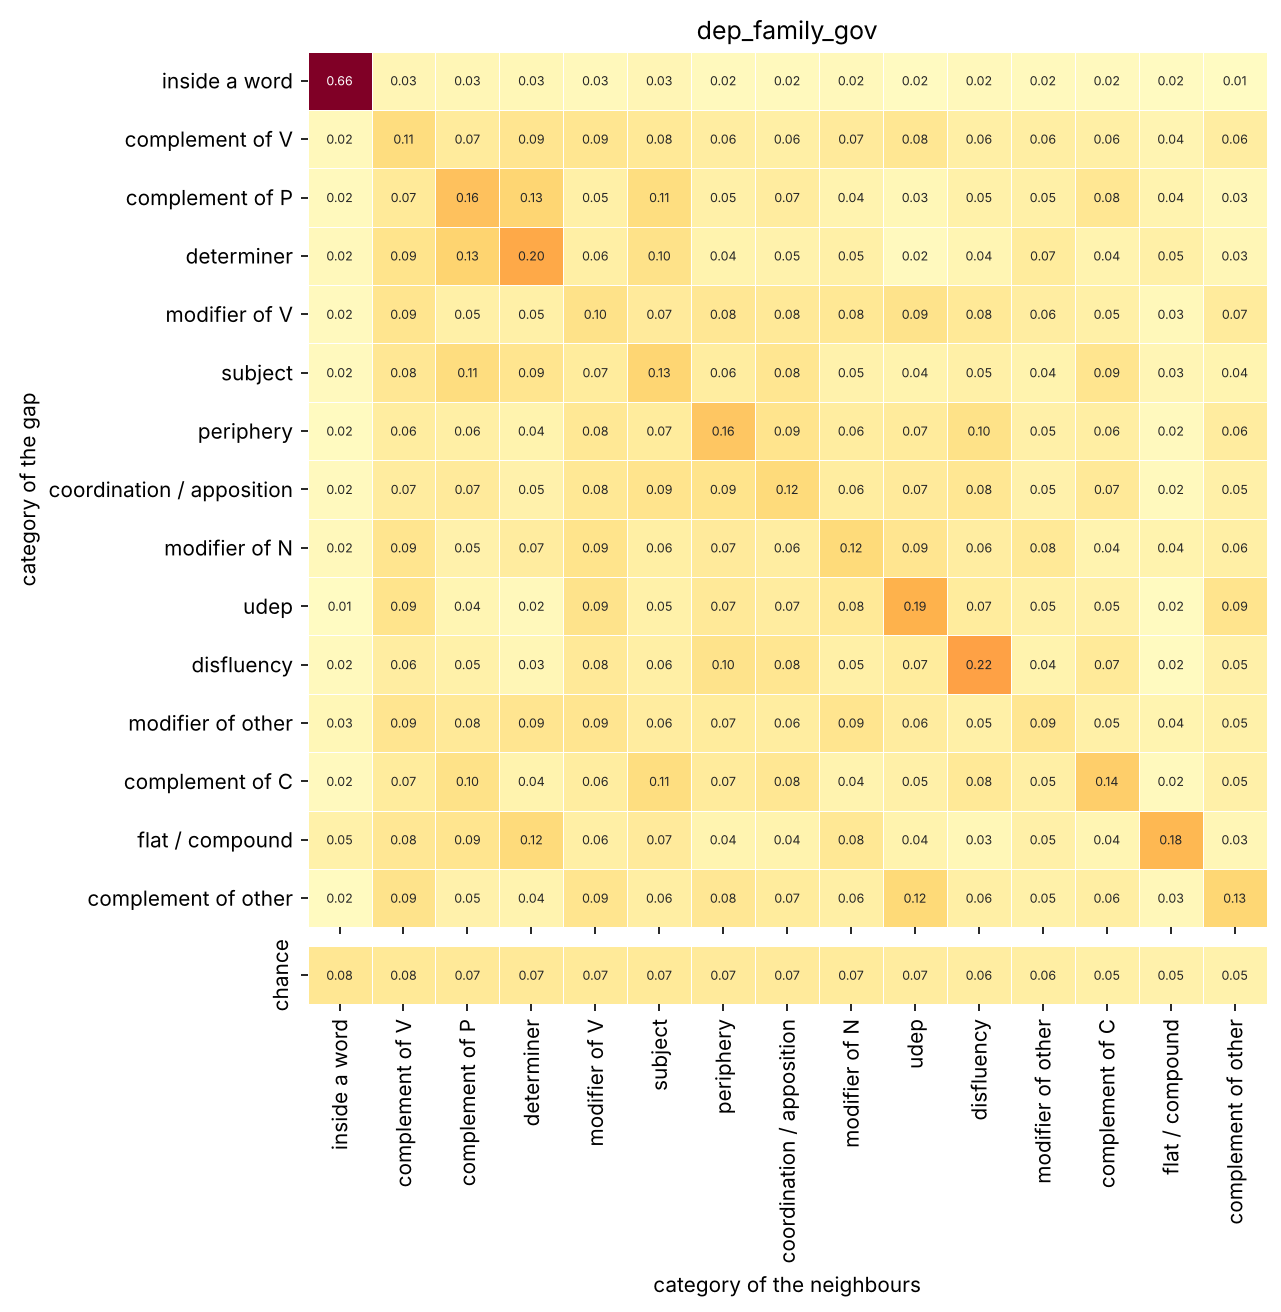

In [14]:
# CHOSEN = tuple(RANKING.candidate.iloc[0].split(" & "))
# CHOSEN = "dep_inner_dir"
# CHOSEN = ("after_word_class",)
# CHOSEN = ("dep_inner_dir",)
CHOSEN = ("dep_family_gov",)                      # NEW: relation families, comp / mod split by governor
# CHOSEN = ("dep_family_gov", "dep_inner_dir")    # … and the direction of the relation
OVERLAP_MIN = 0.05            # report off-diagonal cells at least this far above chance
MAX_SHOWN = 40                # largest categories shown in the heatmap


def full_stability(nb, labels, cats, n_perm, rng):
    C = len(cats)
    observed, S, has = stability(nb, labels, C)
    chance = np.zeros((C, C))
    for _ in range(n_perm):
        chance += stability(nb, rng.permutation(labels), C)[0]
    chance /= n_perm
    table = pd.DataFrame({"gaps": np.bincount(labels, minlength=C),
                          "stability": np.diag(observed), "chance": np.diag(chance)}, index=cats)
    table["kappa"] = (table["stability"] - table["chance"]) / (1 - table["chance"])
    obs_df, ch_df = pd.DataFrame(observed, cats, cats), pd.DataFrame(chance, cats, cats)
    over = (obs_df - ch_df).stack()
    over = over[(over.index.get_level_values(0) != over.index.get_level_values(1)) & (over >= OVERLAP_MIN)]
    overlaps = pd.DataFrame({"observed": obs_df.stack()[over.index], "chance": ch_df.stack()[over.index],
                             "excess": over}).sort_values("excess", ascending=False)
    overlaps.index.names = ["gaps of", "neighbours in"]
    return obs_df, ch_df, table, overlaps


def plot_stability(obs_df, ch_df, table, title, vmax=0.5):
    shown = table.sort_values("gaps", ascending=False).index[:MAX_SHOWN]
    obs, chance_col = obs_df.loc[shown, shown], ch_df.loc[shown, shown].mean(axis=0)
    n = len(shown)
    fig, (ax, axc) = plt.subplots(2, 1, figsize=(0.35 * n + 3, 0.35 * n + 3), dpi=150, sharex=True,
                                  gridspec_kw={"height_ratios": [n, 1], "hspace": 0.04})
    kw = dict(cmap="YlOrRd", vmin=0, vmax=vmax, annot=n <= 25, fmt=".2f", annot_kws={"size": 6},
              cbar=False, linewidths=0.3, linecolor="white")
    sns.heatmap(obs, ax=ax, **kw)
    sns.heatmap(chance_col.to_frame().T, ax=axc, yticklabels=["chance"], **kw)
    axc.tick_params(axis="x", rotation=90)
    ax.set_title(title); ax.set_ylabel("category of the gap"); axc.set_xlabel("category of the neighbours")
    return fig


keep, labels, cats = categorisation(CHOSEN)
nb_chosen = restrict(NB, keep)
obs_df, ch_df, table, overlaps = full_stability(nb_chosen, labels, cats, N_PERM, np.random.default_rng(SEED))
print(f"{' & '.join(CHOSEN)}: {len(cats)} categories, {keep.sum()} gaps ({100 * keep.mean():.0f}% covered); "
      f"mean kappa {table['kappa'].mean():.3f}")
print(table.sort_values("kappa", ascending=False).round(3).to_string())
print("\noverlaps:")
print(overlaps.round(3).head(25).to_string())
plot_stability(obs_df, ch_df, table, " & ".join(CHOSEN));

## Step 6 — which descriptor (if any) divides each category? (the word notebook's Step 2)
Within one category, neighbours are recomputed among its own gaps only, as in `split_test()`. Each descriptor not already in `CHOSEN` is tried as a split.

A split is eligible only if every value it takes in the category has at least `MIN_CAT` gaps. Rare values are not pooled into a residual group.

The best split with p < `ALPHA` and kappa ≥ `KAPPA_MIN` is kept.

Kappas are lower here than in the word study, where each unit pooled many occurrences; a single gap is a noisier unit. So `KAPPA_MIN = 0.20` is strict at this level: lower it to see weaker splits.

In [15]:
N_PERM_SPLIT = N_PERM         # lower it (e.g. 200) for a quicker first look


def split_tests(cat_index, rng):
    rows = np.where(keep)[0][labels == cat_index]           # gap indices of this category
    sub = GAPS_DF.iloc[rows]
    nb = gap_neighbours(GAP_M[rows], rng)
    out = []
    for attr in BASE:
        if attr in CHOSEN:
            continue
        values = sub[attr].astype(str).to_numpy()
        names, counts = np.unique(values, return_counts=True)
        if len(names) < 2 or counts.min() < MIN_CAT:
            continue
        lab = np.searchsorted(names, values)
        res = kappa_test(nb, lab, len(names), N_PERM_SPLIT, rng)
        out.append(dict(category=cats[cat_index], attr=attr,
                        groups=", ".join(f"{v}:{n}" for v, n in sorted(zip(names, counts), key=lambda x: -x[1])),
                        **res))
    return pd.DataFrame(out)


t0 = time.time()
rng = np.random.default_rng(SEED)
SPLIT_RESULTS, SPLIT = {}, {}
for ci, cat in enumerate(cats):
    df = split_tests(ci, rng)
    if len(df):
        df = df.sort_values("kappa", ascending=False).reset_index(drop=True)
    SPLIT_RESULTS[cat] = df
    ok = df[(df["p"] < ALPHA) & (df["kappa"] >= KAPPA_MIN)] if len(df) else df
    SPLIT[cat] = ok.iloc[0]["attr"] if len(ok) else None
print(f"{time.time() - t0:.0f}s")

with pd.option_context("display.width", 250, "display.max_colwidth", 80):
    for cat in cats:
        print(f"\n{cat}: split = {SPLIT[cat] or 'none'}")
        if len(SPLIT_RESULTS[cat]):
            print(SPLIT_RESULTS[cat][["attr", "groups", "same", "chance", "kappa", "p"]].round(3).to_string(index=False))

27s

complement of C: split = class_after
       attr                   groups  same  chance  kappa     p
class_after function:330, content:37 0.600   0.496  0.207 0.004
  flux_size 1:224, 2:68, 3:44, 4+:31 0.263   0.246  0.023 0.232

complement of P: split = class_after
       attr                       groups  same  chance  kappa     p
class_after  content:1664, function:1259 0.662   0.500  0.323 0.001
  flux_size 1:1324, 2:866, 3:455, 4+:278 0.252   0.249  0.004 0.295

complement of V: split = class_after
         attr                                                                            groups  same  chance  kappa     p
  class_after                                                       function:2028, content:1668 0.658   0.500  0.315 0.001
 class_before                                                       content:2377, function:1319 0.626   0.500  0.253 0.001
dep_inner_dir                                                                     →:3205, ←:491 0.601   0.500  0.202 

## Step 7 — the refined categorisation and its stability matrix (the word notebook's Step 3)

27 refined categories (from 15); smallest has 37 gaps


mean kappa 0.089 (before refinement 0.122)
                                              gaps  stability  chance  kappa
inside a word | class_after=content          10658      0.528   0.051  0.502
inside a word | class_after=function           834      0.328   0.040  0.300
disfluency | dep_inner_rel=reparandum          627      0.157   0.038  0.124
flat / compound                                262      0.143   0.032  0.115
periphery | class_after=content               1090      0.142   0.041  0.106
complement of P | class_after=content         1664      0.141   0.043  0.102
determiner                                    2805      0.135   0.045  0.094
complement of P | class_after=function        1259      0.131   0.042  0.093
udep                                           938      0.116   0.041  0.079
modifier of N | class_after=content            948      0.113   0.040  0.076
complement of C | class_after=content           37      0.086   0.014  0.073
coordination / apposition | dep_i

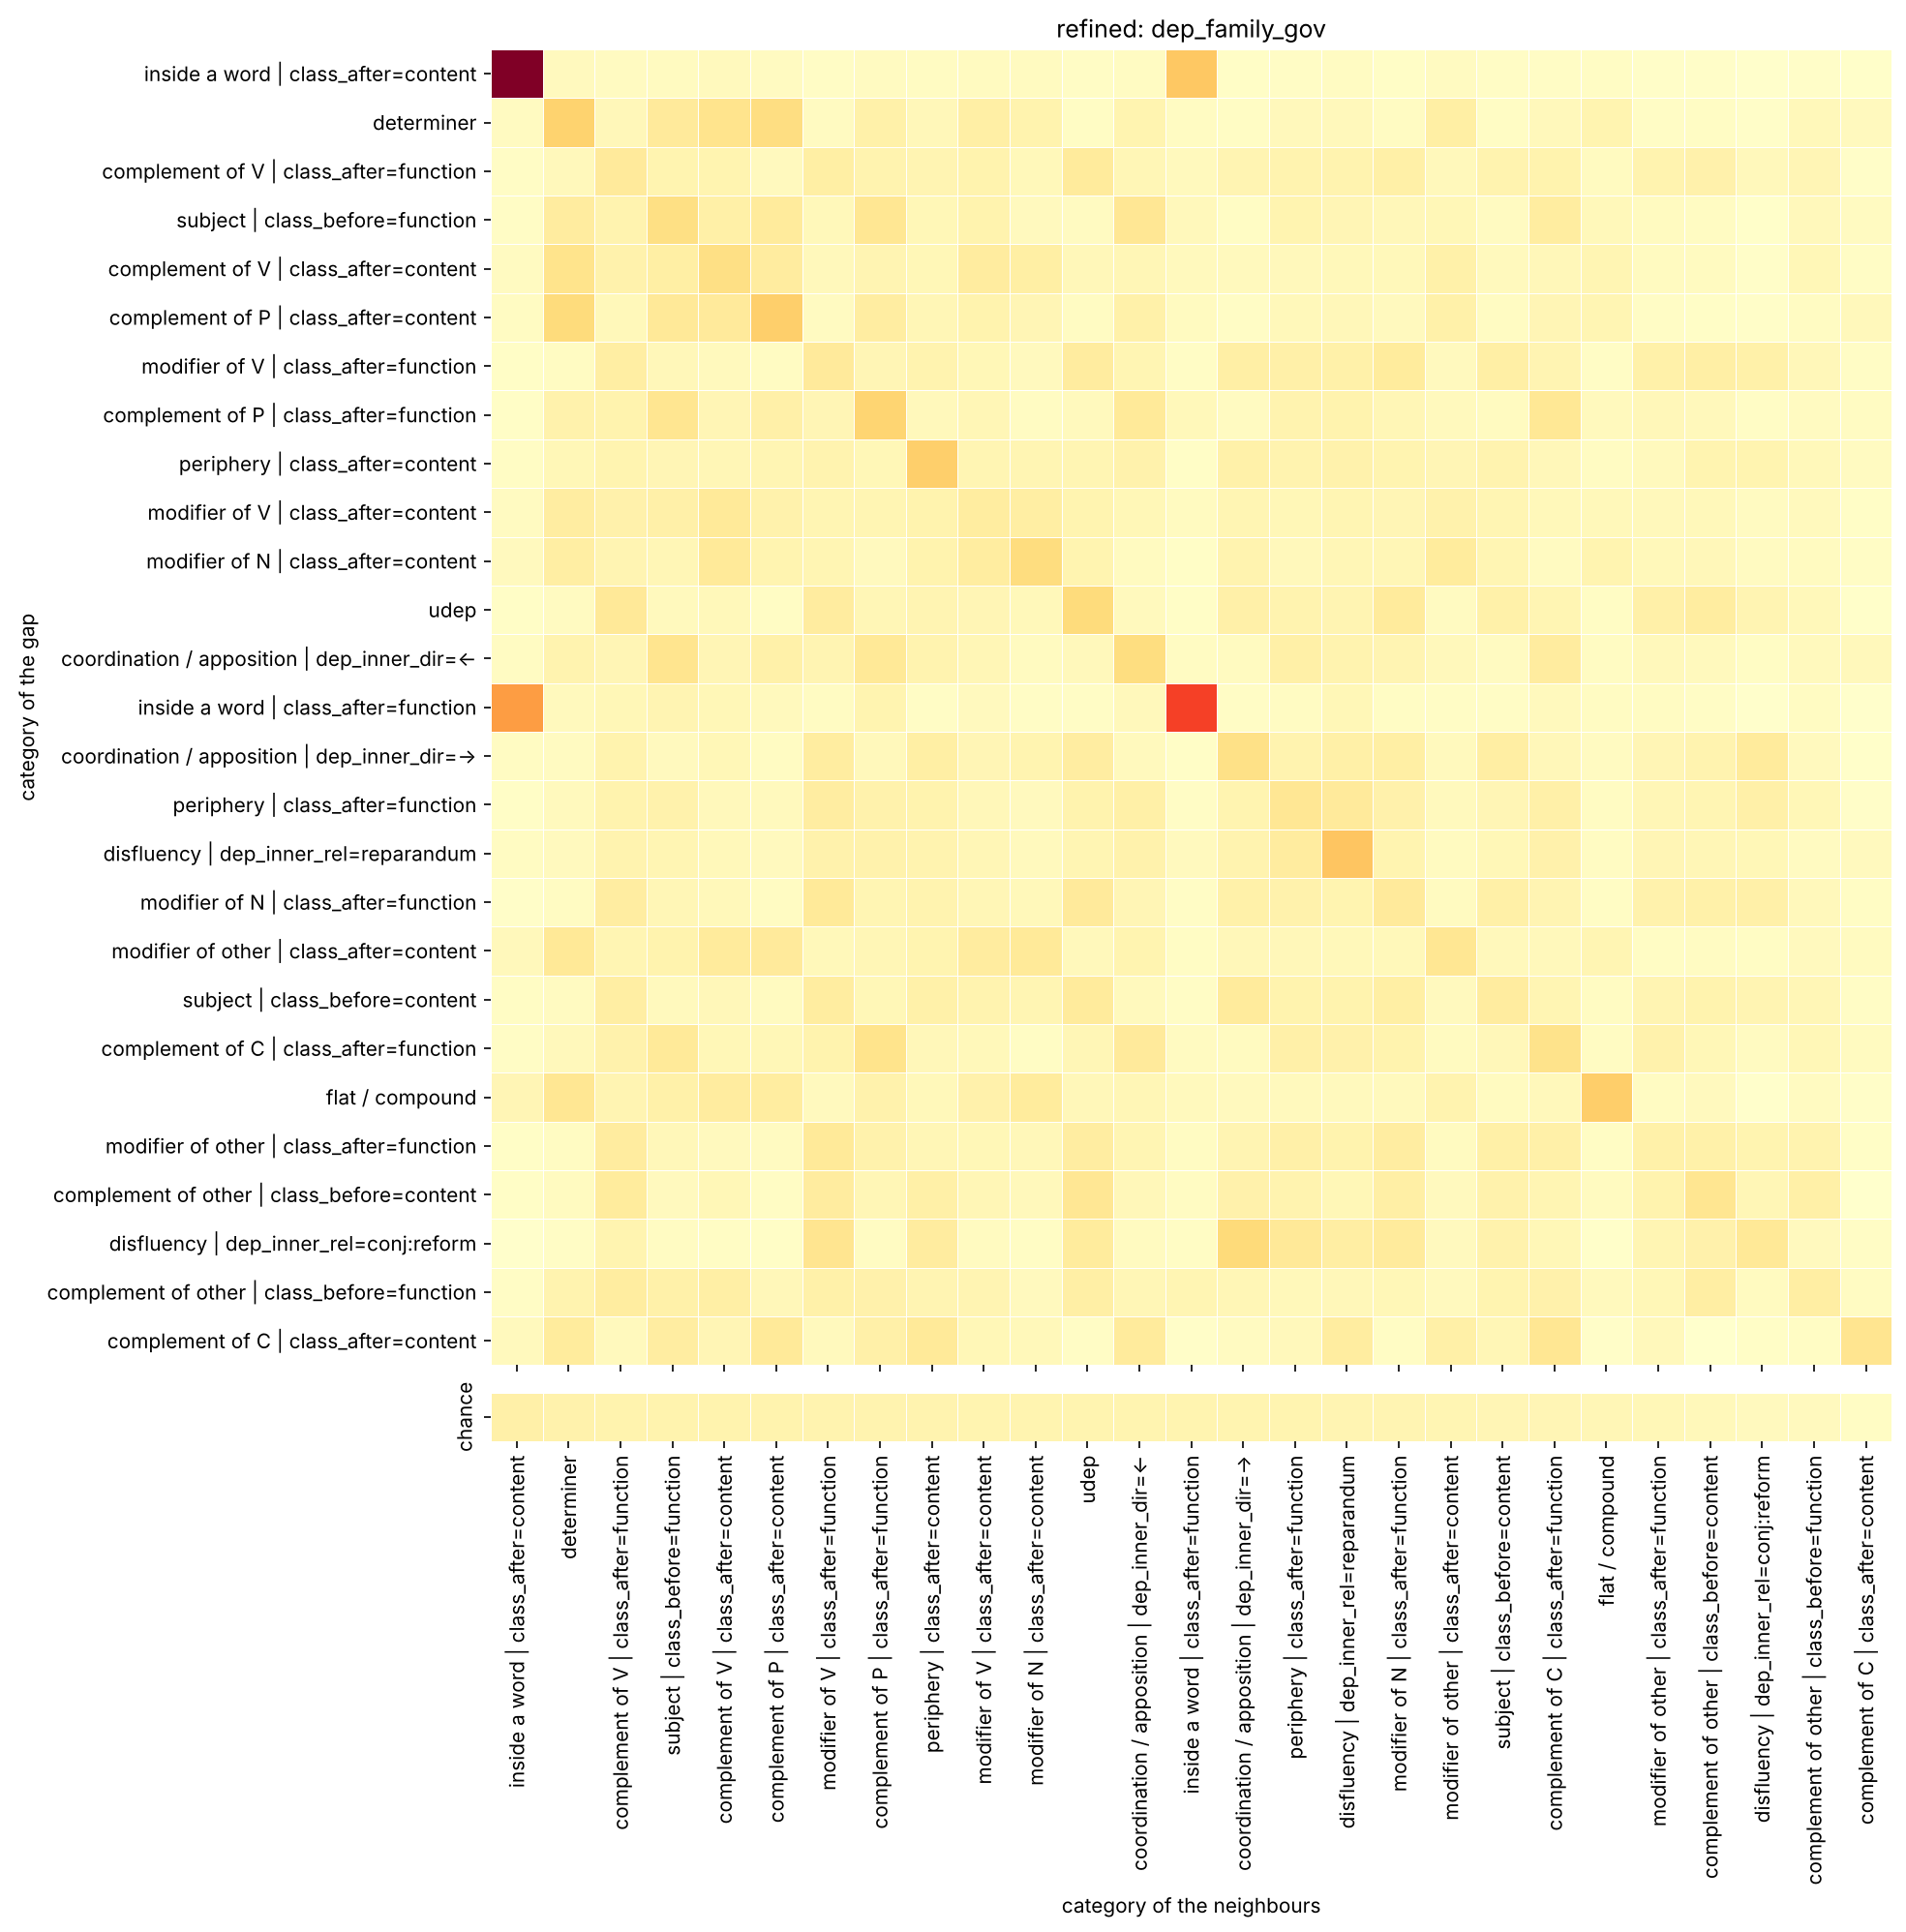

In [16]:
def refined(i_gap, cat):
    attr = SPLIT[cat]
    return cat if attr is None else f"{cat} | {attr}={GAPS_DF.iloc[i_gap][attr]}"


gap_ids = np.where(keep)[0]
ref = np.array([refined(i, cats[c]) for i, c in zip(gap_ids, labels)])
ref_names, ref_counts = np.unique(ref, return_counts=True)
REF_CATS = list(ref_names)
ref_labels = np.searchsorted(ref_names, ref)
print(f"{len(REF_CATS)} refined categories (from {len(cats)}); smallest has {ref_counts.min()} gaps")

obs_ref, ch_ref, table_ref, overlaps_ref = full_stability(nb_chosen, ref_labels, REF_CATS, N_PERM,
                                                          np.random.default_rng(SEED))
print(f"mean kappa {table_ref['kappa'].mean():.3f} (before refinement {table['kappa'].mean():.3f})")
print(table_ref.sort_values("kappa", ascending=False).round(3).to_string())
print("\noverlaps:")
print(overlaps_ref.round(3).head(25).to_string())
plot_stability(obs_ref, ch_ref, table_ref, "refined: " + " & ".join(CHOSEN));

In [17]:
# Examples of gaps from one category (change the name)
example_cat = table.sort_values("kappa", ascending=False).index[0]
sel = gap_ids[labels == cats.index(example_cat)]
for ex in GAPS_DF.iloc[sel]["context"].sample(min(10, len(sel)), random_state=SEED):
    print("·", ex)

· pour restaurer la dignité[di‖nji] de la personne
· vais apprendre la sténodactylo[no‖dak]
· Jean François[fRa~‖swa] Saluzzo est lui
· et de nos partenaires[paR‖t@]
· plus ou moins collaboré[la‖bO] et que au
· y a par exemple[REg‖za~pl] des des formes
· est vrai avec Jean-François[Za~‖fRa~] Alain Alexandre XXX
· a la nouvelle génération[ne‖Ra] tout ci euh
· musique la jeune Pologne[lO‖nja~] en musique avec
· je les vois rentrer[Ra~‖tReZ] je me dis


# Part 2 — following the meeting with Sylvain (15 October)
Part 1 has three changes, marked `NEW`:
* **Step 1:** `PAIR_FEATURES = True` adds two features of the pair of syllables (F0 jump, duration ratio). Set it to `False` for the original 50 features.
* **Step 2:** `dep_family` and `dep_family_gov` are the relation families, with complements and modifiers split by the class of their governor.
* **Step 5:** `CHOSEN = ("dep_family_gov",)`, so Steps 5–7 show the stability matrix, the split tests and the refined categories of these families.

The steps below compare two categories (Step 8), group the categories that prosody cannot tell apart (Step 9, optional), and ask whether the acoustics predict the prominences listeners heard (Step 10).

## Step 8 — what distinguishes the gaps of two categories?
This is `shared_table()` from the word notebook, for two categories. A category's **profile** is the share of its gaps that carry each feature. The **average category** is the mean of the profiles, with each category counting once. The table lists the features on which the two categories differ most, in percentage points. It keeps one value per variable: for example, only the most different of `before:Dur_short / mid / long`. The second table gives the medians of the raw measures.

                              determiner  udep  average category  difference
after:Group=Begin                   17.0  78.0              46.0       -61.0
before:Group=End                    17.0  77.0              48.0       -60.0
pair:Dur_ratio=after_shorter        18.0  68.0              43.0       -50.0
after:Foot=End                      79.0  31.0              49.0        47.0
after:Package=End                   57.0  11.0              32.0        46.0
before:Foot=End                     39.0  80.0              56.0       -41.0
pair:F0_jump=down                   22.0  62.0              40.0       -40.0
before:Package=End                  10.0  47.0              34.0       -37.0
before:Prominence=Strong            11.0  46.0              29.0       -34.0
before:Dur_long                     19.0  51.0              37.0       -33.0
after:Dur_short                     22.0  55.0              37.0       -32.0
before:F0_high                      22.0  45.0              37.0       -23.0

                              determiner    udep  all gaps
duration before (ms)              139.00  201.50    158.00
duration after (ms)               180.00  129.00    160.00
F0 before (st)                     -0.98    0.24     -0.37
F0 after (st)                      -0.30   -1.13     -0.36
F0 jump (st)                        0.35   -1.32     -0.18
log2 duration after / before        0.44   -0.67      0.10

determiner:
  · qui va mettre le ‖ ballon dans la petite
  · vraiment ouverte sur le ‖ monde
  · que euh dans le ‖ sixième arrondissement les maternelles
  · il y a une ‖ banque pour vous repérer
  · quatre nuits ou trois ‖ nuits à à ramper

udep:
  · d' écrire sans jouissance ‖ de lire
  · habitant dans le centre ‖ de Paris euh les
  · un grand nombre ‖ des enfants qui vont
  · notamment de l' art ‖ comme quelque chose qui
  · droites coalisées nos combats ‖ pour la conquête du


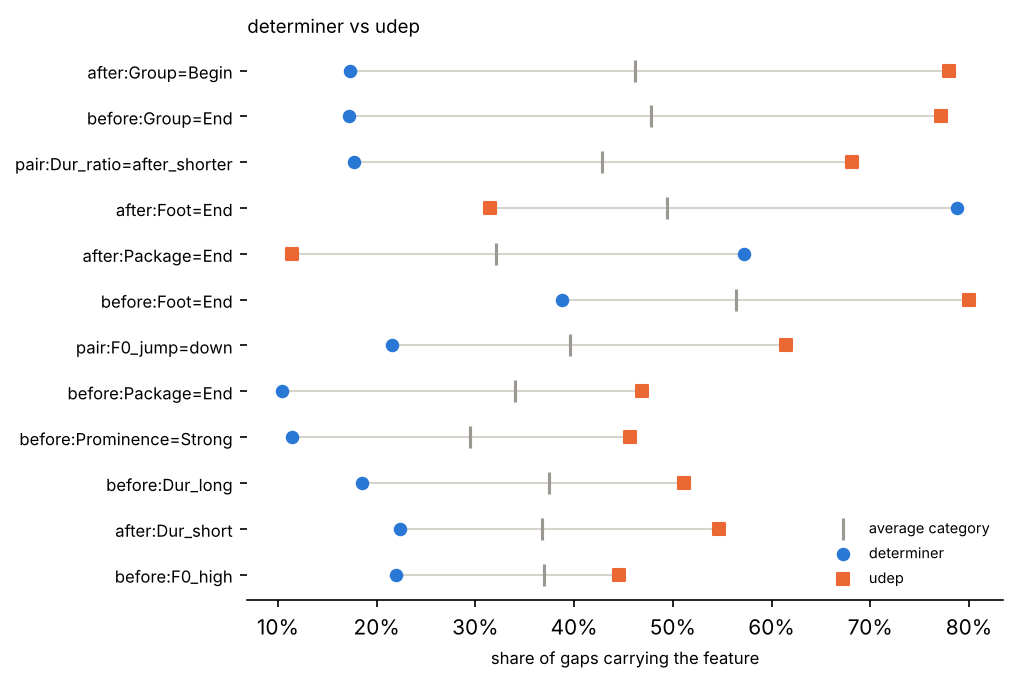

In [18]:
# ── Step 8: what distinguishes the gaps of two categories? ───────────────────
COMPARE_ON = "dep_family_gov"
C0, C1 = "determiner", "udep"
FEATS = [idx2feature[j] for j in range(GAP_M.shape[1])]


def variable_of(f):
    """'before:Group=End' -> 'before:Group', 'after:Dur_long' -> 'after:Dur', 'pair:F0_jump=up' -> 'pair:F0_jump'"""
    side, rest = f.split(":", 1)
    return f"{side}:{rest.split('=')[0]}" if "=" in rest else f"{side}:{rest.split('_')[0]}"


def profiles(col):
    """Share of each category's gaps carrying each feature, and the average category."""
    lab = GAPS_DF[col].astype(str).to_numpy()
    cats_ = [c for c, n in Counter(lab).items() if n >= MIN_CAT]
    P = pd.DataFrame({c: GAP_M[lab == c].mean(0) for c in cats_}, index=FEATS)
    return P, P.mean(axis=1)


def compare(col, c0, c1, k=12):
    """The k features on which c0 and c1 differ most (one value per variable)."""
    P, ref = profiles(col)
    t = pd.DataFrame({"variable": [variable_of(f) for f in FEATS], c0: P[c0], c1: P[c1],
                      "average category": ref, "difference": P[c0] - P[c1]})
    t = t.loc[t.groupby("variable")["difference"].apply(lambda s: s.abs().idxmax())]
    return t.reindex(t["difference"].abs().sort_values(ascending=False).index).head(k).drop(columns="variable")


def medians(col, c0, c1):
    """Medians of the raw measures of the two syllables."""
    rows_ = []
    for g in GAPS:
        a, b = (g["sent"]["syllables"][kk]["misc"] for kk in (g["k"], g["k"] + 1))
        rows_.append({"duration before (ms)": _number(a.get("Duration")),
                      "duration after (ms)": _number(b.get("Duration")),
                      "F0 before (st)": _number(a.get("SemitonesFromUtteranceMean")),
                      "F0 after (st)": _number(b.get("SemitonesFromUtteranceMean")),
                      "F0 jump (st)": g["pair"]["F0_jump"],
                      "log2 duration after / before": g["pair"]["Dur_ratio"]})
    X = pd.DataFrame(rows_, dtype=float)
    lab = GAPS_DF[col].astype(str).to_numpy()
    return pd.DataFrame({c0: X[lab == c0].median(), c1: X[lab == c1].median(), "all gaps": X.median()})


def plot_compare(t, c0, c1):
    t = t.iloc[::-1]
    fig, ax = plt.subplots(figsize=(6.5, 0.3 * len(t) + 1.2), dpi=150)
    y = np.arange(len(t))
    ax.hlines(y, t[[c0, c1]].min(axis=1), t[[c0, c1]].max(axis=1), color="#d6d4cc", lw=1, zorder=1)
    ax.scatter(t["average category"], y, marker="|", s=120, color="#9a9890", label="average category", zorder=2)
    ax.scatter(t[c0], y, s=30, color="#2a78d6", label=c0, zorder=3)
    ax.scatter(t[c1], y, s=30, marker="s", color="#eb6834", label=c1, zorder=3)
    ax.set_yticks(y, t.index, fontsize=8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of gaps carrying the feature", fontsize=8)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.legend(fontsize=7, frameon=False, loc="lower right")
    ax.set_title(f"{c0} vs {c1}", fontsize=9, loc="left")
    return fig


T_COMPARE = compare(COMPARE_ON, C0, C1)
print((100 * T_COMPARE).round(0).to_string())
print()
print(medians(COMPARE_ON, C0, C1).round(2).to_string())
for c in (C0, C1):
    print(f"\n{c}:")
    for x in GAPS_DF.loc[GAPS_DF[COMPARE_ON] == c, "context"].sample(5, random_state=SEED):
        print("  ·", x)
plot_compare(T_COMPARE, C0, C1);


## Step 9 (optional) — which categories can prosody tell apart?
**Pairwise κ.** For two categories A and B, take only their gaps, find each gap's 20 nearest neighbours among them, and compute κ as in Step 4. With two categories, chance is 0.5, so κ = (stability − 0.5) / 0.5:
* κ = 0: a gap's neighbours are as mixed as after shuffling the labels, so prosody cannot tell A from B;
* κ = 0.20: 60% of its neighbours are in its own category instead of 50%;
* κ = 1: all of them are.

**The tree.** The two categories with the lowest κ are joined first, then the next lowest, and so on. When a branch holds several categories, its κ with another branch is the mean of the pairwise κ between their categories (average linkage). The x-axis gives the κ at which two branches join: far left means prosodically almost identical, far right means clearly different.

**Reading it.** Only the branching matters. Two categories are close if they join near the left, wherever they sit on the page; the leaves are ordered only so that branches do not cross. The dashed line is `KAPPA_MIN` = 0.20, the threshold of the split test (Step 6). The branches that join to its left are categories prosody does not reliably separate, and each such group gets its own colour. Joins to the right of the line show how far apart the groups are. A category with grey lines joins nothing below 0.20.

22 categories, 231 pairs tested in 24s
group 1 (1362 gaps): disfluency ←, periphery ←
group 2 (852 gaps): coordination / apposition →, disfluency →
group 3 (7742 gaps): complement of V →, complement of other →, modifier of N →, modifier of V ←, modifier of V →, modifier of other →, udep →
group 4 (1093 gaps): periphery →
group 5 (6321 gaps): complement of C →, complement of P →, coordination / apposition ←, subject ←, subject →
group 6 (973 gaps): modifier of N ←, modifier of other ←
group 7 (3296 gaps): complement of V ←, determiner ←
group 8 (261 gaps): flat / compound →


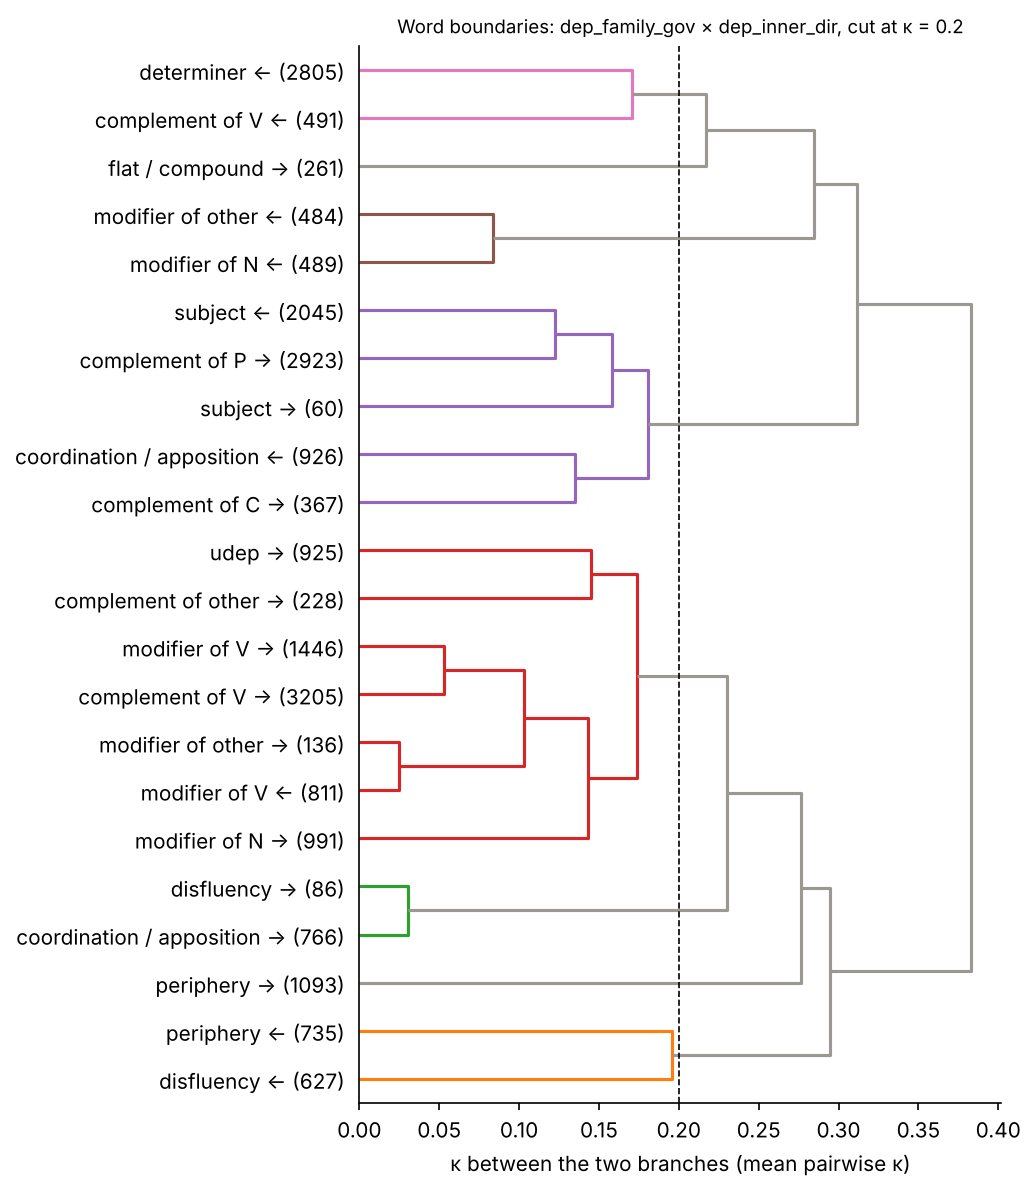

In [19]:
# ── Step 9 (optional): which categories can prosody tell apart? ───────────────
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform

TREE_ON = ("dep_family_gov", "dep_inner_dir")             # leaves: family × governor × direction
WORD_BOUNDARIES = (GAPS_DF["gap_type"] == "word boundary").to_numpy()


def pair_kappa(cols, mask):
    """κ for every pair of categories: the two categories' gaps alone, neighbours recomputed among them."""
    lab = GAPS_DF[list(cols)].astype(str).agg(" ".join, axis=1).to_numpy()
    lab[~mask] = ""
    names = sorted(c for c, n in Counter(lab[mask]).items() if n >= MIN_CAT)
    rng_ = np.random.default_rng(SEED)
    K = pd.DataFrame(0.0, index=names, columns=names)
    for a, b in combinations(names, 2):
        rows_ = np.where((lab == a) | (lab == b))[0]
        nb_ = gap_neighbours(GAP_M[rows_], rng_)
        K.loc[a, b] = K.loc[b, a] = kappa_test(nb_, (lab[rows_] == b).astype(int), 2, N_PERM_RANK, rng_)["kappa"]
    return K, Counter(lab[mask])


t0 = time.time()
PAIR_K, sizes = pair_kappa(TREE_ON, WORD_BOUNDARIES)
print(f"{len(PAIR_K)} categories, {len(PAIR_K) * (len(PAIR_K) - 1) // 2} pairs tested in {time.time() - t0:.0f}s")

TREE = linkage(squareform(PAIR_K.clip(lower=0).to_numpy(), checks=False), method="average")
GROUP_OF = dict(zip(PAIR_K.index, fcluster(TREE, t=KAPPA_MIN, criterion="distance")))
for g in sorted(set(GROUP_OF.values())):
    members = [c for c, x in GROUP_OF.items() if x == g]
    print(f"group {g} ({sum(sizes[c] for c in members)} gaps): " + ", ".join(members))

fig, ax = plt.subplots(figsize=(7, 0.32 * len(PAIR_K) + 1), dpi=150)
dendrogram(TREE, labels=[f"{c} ({sizes[c]})" for c in PAIR_K.index], orientation="right",
           color_threshold=KAPPA_MIN, above_threshold_color="#9a9890", ax=ax)
ax.axvline(KAPPA_MIN, ls="--", c="k", lw=0.8)
ax.set_xlabel("κ between the two branches (mean pairwise κ)")
ax.set_title(f"Word boundaries: {' × '.join(TREE_ON)}, cut at κ = {KAPPA_MIN}", fontsize=9)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()


## Step 10 — can the acoustics predict the prominences listeners heard?
Rhapsodie's prominences were marked by listeners who understood what was said. If their knowledge of the words or the syntax shaped what they heard, the words and the syntax should predict the marked prominences *beyond* what the signal predicts.

**Unit.** One syllable, the first or the last of its word (prominence is only stored there), with duration, F0 and amplitude measured.

**Target.** 1 if the syllable was marked prominent (Weak or Strong), 0 otherwise.

**Features**, in five blocks:
1. *own syllable*: log duration; F0 (semitones from the utterance mean); loudness (amplitude minus the utterance's mean amplitude, in dB); and the binned pitch range, slope and height;
2. *neighbouring syllables*: how much longer, higher and louder the syllable is than the previous and the next syllable;
3. *pauses*: the silent pause after the word (for its last syllable) and before it (for its first syllable);
4. *word*: POS, function or content word, and whether the syllable is the only, first or last syllable of the word;
5. *structure*: the word's relation family, whether its governor is before or after it, and how many phrases end or start with it.

**Model.** Logistic regression: each feature gets a weight, the weighted sum is turned into a probability between 0 and 1, and the weights are learned from the data. The recordings are split into 5 folds. The model learns on 4 and gives probabilities for the 5th, in turn, so every probability comes from a model that never heard that speaker.

**AUC.** Take a random prominent syllable and a random non-prominent one. AUC is how often the prominent one gets the higher probability: 0.5 = chance, 1 = always.

In [20]:
# ── Step 10a: one row per syllable ─────────────────────────────────────────────
def _amp(sy):
    return _number(sy["misc"].get("AvgAmplitude"))       # dB; the 0.0 sentinel -> None


def pause_after(t):
    return _number(t["misc"].get("NextBreakLength")) or 0.0           # seconds; 0 if no pause


def syllable_rows(s):
    tok, syl = s["tokens"], s["syllables"]
    amps = [a for sy in syl if (a := _amp(sy)) is not None]
    amp_mean = np.mean(amps) if amps else np.nan                       # loudness is relative to the utterance
    n_close = Counter(max(c) for c, lab in s["constituents"] if is_phrase(lab))   # phrases ending on each word
    n_open = Counter(min(c) for c, lab in s["constituents"] if is_phrase(lab))    # phrases starting on each word
    vals = [dict(dur=_number(sy["misc"].get("Duration")),
                 f0=_number(sy["misc"].get("SemitonesFromUtteranceMean")),
                 amp=(_amp(sy) or np.nan) - amp_mean) for sy in syl]
    for k, sy in enumerate(syl):
        t = max(sy["toks"])
        if t not in tok or vals[k]["dur"] is None or vals[k]["f0"] is None or np.isnan(vals[k]["amp"]):
            continue                                                   # not fully measured
        m = tok[t]["misc"]
        if "Overlap" in (m.get("ProminenceFinal"), m.get("ProminenceInitial")):
            continue                                                   # overlapping speech: no annotation
        first, last = s["first"][t] == k, s["last"][t] == k
        if not (first or last):
            continue                       # prominence is stored only for first and last syllables
        if (m.get("ProminenceFinal") if last else m.get("ProminenceInitial")) == "Pause":
            continue                       # "Pause" (after a pause) is not a prominence label: unknown
        p = prominence(s, k)               # Step 1's function: Weak, Strong or None
        r = dict(file=s["sent_id"].split("-")[0], word=tok[t]["form"], syllable=sy["misc"].get("SylForm"),
                 prominent=int(p is not None), strong=int(p == "Strong"),
                 # 1. the syllable's own acoustics
                 log_dur=np.log(vals[k]["dur"]), f0=vals[k]["f0"], amp=vals[k]["amp"],
                 pitch_range=sy["misc"].get("PitchRangeGlo", "X"), slope=sy["misc"].get("SlopeGlo", "X"),
                 height=sy["misc"].get("AvgHeightGlo", "X"),
                 # 3. pauses (log of 1 + milliseconds)
                 pause_after=np.log1p(1000 * pause_after(tok[t])) if last else 0.0,
                 pause_before=np.log1p(1000 * pause_after(tok[t - 1])) if first and t - 1 in tok else 0.0,
                 # 4. the word
                 upos=tok[t]["upos"], word_class="function" if tok[t]["upos"] in FUNCTION_POS else "content",
                 position="only" if first and last else "final" if last else "initial",
                 # 5. the word's place in the structure
                 rel=family(tok[t]["rel"].split("@")[0]),
                 head_side="root" if tok[t]["head"] not in tok else "head after" if tok[t]["head"] > t else "head before",
                 n_close=cap(n_close[t]) if last else "not final", n_open=cap(n_open[t]) if first else "not initial")
        # 2. the syllable compared with the previous and the next syllable
        for side, j in (("prev", k - 1), ("next", k + 1)):
            ok = 0 <= j < len(syl) and vals[j]["dur"] is not None and vals[j]["f0"] is not None
            r[f"{side}_ok"] = int(ok)
            r[f"{side}_dur_ratio"] = np.log(vals[k]["dur"] / vals[j]["dur"]) if ok else 0.0
            r[f"{side}_f0_diff"] = vals[k]["f0"] - vals[j]["f0"] if ok else 0.0
            r[f"{side}_amp_diff"] = vals[k]["amp"] - vals[j]["amp"] if ok and not np.isnan(vals[j]["amp"]) else 0.0
        yield r


SYL = pd.DataFrame([r for s in SENTS for r in syllable_rows(s)])
print(f"{len(SYL)} syllables from {SYL.file.nunique()} recordings; "
      f"prominent: {SYL.prominent.mean():.1%} (strong: {SYL.strong.mean():.1%})")
print(SYL.groupby("position").prominent.agg(["size", "mean"]).round(3).to_string())


32502 syllables from 57 recordings; prominent: 49.6% (strong: 30.0%)
           size   mean
position              
final      7303  0.803
initial    8176  0.365
only      17023  0.426


In [21]:
# ── Step 10b: how well does each block of features predict the prominences? ─────
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

BLOCKS = {
    "own syllable": ["log_dur", "f0", "amp", "pitch_range", "slope", "height"],
    "neighbouring syllables": [f"{s}_{m}" for s in ("prev", "next") for m in ("ok", "dur_ratio", "f0_diff", "amp_diff")],
    "pauses": ["pause_after", "pause_before"],
    "word": ["upos", "word_class", "position"],
    "structure": ["rel", "head_side", "n_close", "n_open"],
}
ACOUSTIC = ["own syllable", "neighbouring syllables", "pauses"]
MODELS = {"acoustic: own syllable": ["own syllable"],
          "+ neighbouring syllables": ["own syllable", "neighbouring syllables"],
          "+ pauses (= all acoustic)": ACOUSTIC,
          "word only": ["word"],
          "word + structure": ["word", "structure"],
          "all acoustic + word": ACOUSTIC + ["word"],
          "all acoustic + word + structure": ACOUSTIC + ["word", "structure"]}


def design(blocks):
    """Numbers stay numbers; each category (e.g. upos=DET) becomes a 0/1 column."""
    cols = [c for b in blocks for c in BLOCKS[b]]
    return pd.get_dummies(SYL[cols], columns=[c for c in cols if not pd.api.types.is_numeric_dtype(SYL[c])],
                          dtype=float)


CV = GroupKFold(5)          # 5 folds of whole recordings: a speaker is never in both training and test data
PRED, rows_ = {}, []
for name, blocks in MODELS.items():
    X = design(blocks)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    p = cross_val_predict(model, X, SYL.prominent, cv=CV, groups=SYL.file, method="predict_proba")[:, 1]
    PRED[name] = p           # each syllable's probability, from a model that never saw its recording
    rows_.append(dict(model=name, features=X.shape[1], AUC=roc_auc_score(SYL.prominent, p)))
print(pd.DataFrame(rows_).set_index("model").round(3).to_string())

# The weights of the all-acoustic model (fitted on all syllables), per standard deviation of each feature:
# > 0 makes a prominence more likely. Categorical features are compared with their mean.
X = design(ACOUSTIC)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X, SYL.prominent)
READABLE = {"log_dur": "duration", "f0": "F0", "amp": "loudness",
            "prev_dur_ratio": "longer than the previous syllable", "next_dur_ratio": "longer than the next syllable",
            "prev_f0_diff": "higher than the previous syllable", "next_f0_diff": "higher than the next syllable",
            "prev_amp_diff": "louder than the previous syllable", "next_amp_diff": "louder than the next syllable",
            "prev_ok": "has a measured previous syllable", "next_ok": "has a measured next syllable",
            "pause_after": "pause after the word", "pause_before": "pause before the word"}
weights = pd.Series(model[-1].coef_[0], index=[READABLE.get(c, c) for c in X.columns])
print("\nweights of the all-acoustic model:")
print(weights.sort_values(key=abs, ascending=False).round(2).head(12).to_string())


                                 features    AUC
model                                           
acoustic: own syllable                 12  0.766
+ neighbouring syllables               20  0.799
+ pauses (= all acoustic)              22  0.805
word only                              19  0.762
word + structure                       43  0.773
all acoustic + word                    41  0.842
all acoustic + word + structure        65  0.843

weights of the all-acoustic model:
duration                             0.50
higher than the previous syllable    0.41
pause after the word                 0.32
has a measured next syllable        -0.30
longer than the previous syllable    0.27
F0                                   0.25
longer than the next syllable        0.24
slope_Rise                           0.23
higher than the next syllable        0.18
slope_Fall                          -0.15
has a measured previous syllable     0.14
pause before the word               -0.13


Two checks: a more flexible model, and where listeners hear more (or fewer) prominences than the acoustics predict.

In [22]:
# ── Step 10c: two checks ─────────────────────────────────────────────────────────
# 1. A flexible model (boosted trees) combines features by itself ("long AND high").
#    If the word only helped because logistic regression is too simple, the gap would close.
from sklearn.ensemble import HistGradientBoostingClassifier
for name in ("+ pauses (= all acoustic)", "all acoustic + word + structure"):
    p = cross_val_predict(HistGradientBoostingClassifier(random_state=SEED), design(MODELS[name]), SYL.prominent,
                          cv=CV, groups=SYL.file, method="predict_proba")[:, 1]
    print(f"boosted trees, {name}: AUC {roc_auc_score(SYL.prominent, p):.3f}")

# 2. Where do listeners hear more prominences than the acoustics predict?
#    observed = share of syllables marked prominent; acoustic = mean probability given by the
#    all-acoustic model; excess = observed − acoustic. Last syllable of each word.
SYL["p_acoustic"] = PRED["+ pauses (= all acoustic)"]
EXCESS = (SYL[SYL.position.isin(["final", "only"])]
          .groupby(["word_class", "n_close"])
          .agg(syllables=("prominent", "size"), observed=("prominent", "mean"), acoustic=("p_acoustic", "mean")))
EXCESS["excess"] = EXCESS.observed - EXCESS.acoustic
print("\nLast syllable of a word, by the number of phrases ending with the word:")
print(EXCESS.round(3).to_string())


boosted trees, + pauses (= all acoustic): AUC 0.819


boosted trees, all acoustic + word + structure: AUC 0.853



Last syllable of a word, by the number of phrases ending with the word:
                    syllables  observed  acoustic  excess
word_class n_close                                       
content    0             6357     0.713     0.594   0.120
           1             3399     0.698     0.566   0.132
           2             1018     0.826     0.706   0.120
           3              778     0.855     0.774   0.081
           4+            1850     0.897     0.817   0.081
function   0             8053     0.273     0.355  -0.082
           1             2597     0.251     0.371  -0.120
           2              125     0.632     0.675  -0.043
           3               46     0.674     0.726  -0.053
           4+             103     0.854     0.817   0.038
